In [1]:
import os
import sys
import pandas as pd
import numpy as np

sys.path.append(os.path.abspath(".."))

from src.preprocessing import prepare_fairness_data

# Load dataset
df = pd.read_csv("../data/credit_risk_dataset.csv")

# Prepare fairness data
X_train, X_test, y_train, y_test, X_test_raw = prepare_fairness_data(df)

print("===== FAIRNESS DATA PREPARATION =====")
print("Training data:", X_train.shape)
print("Testing data :", X_test.shape)
print("Test labels :", y_test.shape)
print("Raw test data:", X_test_raw.shape)

===== FAIRNESS DATA PREPARATION =====
Training data: (25932, 26)
Testing data : (6484, 26)
Test labels : (6484,)
Raw test data: (6484, 11)


In [2]:
print("===== AGE DISTRIBUTION =====")
print(X_test_raw["person_age"].describe())

print("\n===== INCOME DISTRIBUTION =====")
print(X_test_raw["person_income"].describe())

print("\n===== HOMEOWNERSHIP DISTRIBUTION =====")
print(X_test_raw["person_home_ownership"].value_counts())

print("\n===== AGE VALUE COUNTS =====")
print(X_test_raw["person_age"].value_counts().sort_index())

===== AGE DISTRIBUTION =====
count    6484.000000
mean       27.830197
std         6.335570
min        20.000000
25%        23.000000
50%        26.000000
75%        30.000000
max        80.000000
Name: person_age, dtype: float64

===== INCOME DISTRIBUTION =====
count    6.484000e+03
mean     6.714399e+04
std      5.749765e+04
min      5.000000e+03
25%      3.900000e+04
50%      5.600000e+04
75%      8.000000e+04
max      1.900000e+06
Name: person_income, dtype: float64

===== HOMEOWNERSHIP DISTRIBUTION =====
person_home_ownership
RENT        3264
MORTGAGE    2681
OWN          521
OTHER         18
Name: count, dtype: int64

===== AGE VALUE COUNTS =====
person_age
20      3
21    233
22    734
23    735
24    717
25    591
26    477
27    457
28    388
29    317
30    251
31    231
32    176
33    163
34    152
35    132
36    122
37    108
38     75
39     58
40     60
41     40
42     41
43     36
44     29
45     25
46     19
47     18
48     14
49     12
50      9
51      8
52      

In [4]:
# Create a clean dataset with the same split used by fairness preprocessing
from sklearn.model_selection import train_test_split
df_clean = df.drop_duplicates().copy()

X_raw = df_clean.drop(columns=["loan_status"])
y_raw = df_clean["loan_status"]

X_train_raw, X_test_raw_split, y_train_raw, y_test_raw = train_test_split(
    X_raw,
    y_raw,
    test_size=0.2,
    random_state=42,
    stratify=y_raw
)

# Income thresholds calculated ONLY from training data
income_q1 = X_train_raw["person_income"].quantile(0.25)
income_q3 = X_train_raw["person_income"].quantile(0.75)

print(f"Income Q1: ₹{income_q1:,.0f}")
print(f"Income Q3: ₹{income_q3:,.0f}")

# Age groups
X_test_raw["age_group"] = pd.cut(
    X_test_raw["person_age"],
    bins=[0, 25, 35, float("inf")],
    labels=["Young", "Middle", "Older"],
    right=True
)

# Income groups
X_test_raw["income_group"] = pd.cut(
    X_test_raw["person_income"],
    bins=[-float("inf"), income_q1, income_q3, float("inf")],
    labels=["Low", "Middle", "High"],
    include_lowest=True
)

# Homeownership groups
X_test_raw["homeownership_group"] = X_test_raw["person_home_ownership"]

print("\n===== AGE GROUPS =====")
print(X_test_raw["age_group"].value_counts().sort_index())

print("\n===== INCOME GROUPS =====")
print(X_test_raw["income_group"].value_counts().sort_index())

print("\n===== HOMEOWNERSHIP GROUPS =====")
print(X_test_raw["homeownership_group"].value_counts())

Income Q1: ₹38,400
Income Q3: ₹78,644

===== AGE GROUPS =====
age_group
Young     3013
Middle    2744
Older      727
Name: count, dtype: int64

===== INCOME GROUPS =====
income_group
Low       1577
Middle    3189
High      1718
Name: count, dtype: int64

===== HOMEOWNERSHIP GROUPS =====
homeownership_group
RENT        3264
MORTGAGE    2681
OWN          521
OTHER         18
Name: count, dtype: int64


In [5]:
import os
import sys
import importlib
import numpy as np
import torch

sys.path.append(os.path.abspath(".."))

import src.fairness as fairness
importlib.reload(fairness)

from src.models import train_mlp

# Train the standard MLP using the fairness notebook's data split
standard_model = train_mlp(
    X_train,
    y_train,
    epochs=20,
    batch_size=64,
    learning_rate=0.001
)

# Generate predictions
X_test_tensor = torch.tensor(
    X_test.toarray() if hasattr(X_test, "toarray") else np.asarray(X_test),
    dtype=torch.float32
)

standard_model.eval()

with torch.no_grad():
    logits = standard_model(X_test_tensor)
    probabilities = torch.sigmoid(logits).numpy().flatten()

standard_predictions = (probabilities >= 0.5).astype(int)

# Evaluate by age group
age_results = fairness.evaluate_group_metrics(
    y_true=y_test,
    y_pred=standard_predictions,
    groups=X_test_raw["age_group"]
)

print("===== STANDARD MLP: AGE FAIRNESS =====")
print(age_results.round(4).to_string(index=False))

Epoch [1/20] - Loss: 0.3708
Epoch [2/20] - Loss: 0.2846
Epoch [3/20] - Loss: 0.2636
Epoch [4/20] - Loss: 0.2561
Epoch [5/20] - Loss: 0.2496
Epoch [6/20] - Loss: 0.2446
Epoch [7/20] - Loss: 0.2401
Epoch [8/20] - Loss: 0.2352
Epoch [9/20] - Loss: 0.2335
Epoch [10/20] - Loss: 0.2301
Epoch [11/20] - Loss: 0.2269
Epoch [12/20] - Loss: 0.2259
Epoch [13/20] - Loss: 0.2224
Epoch [14/20] - Loss: 0.2202
Epoch [15/20] - Loss: 0.2186
Epoch [16/20] - Loss: 0.2165
Epoch [17/20] - Loss: 0.2153
Epoch [18/20] - Loss: 0.2157
Epoch [19/20] - Loss: 0.2131
Epoch [20/20] - Loss: 0.2122
===== STANDARD MLP: AGE FAIRNESS =====
 Group  Samples  Accuracy  Precision  Recall     F1  Selection_Rate    FPR    FNR
 Young     3013    0.9193     0.9398  0.6954 0.7993          0.1709 0.0134 0.3046
Middle     2744    0.9271     0.9424  0.7003 0.8035          0.1582 0.0116 0.2997
 Older      727    0.9326     0.9495  0.6812 0.7932          0.1362 0.0085 0.3188


In [6]:
# Calculate disparity between the best and worst age groups
age_gap_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "Selection_Rate",
    "FPR",
    "FNR"
]

age_disparity = {}

for metric in age_gap_metrics:
    gap = age_results[metric].max() - age_results[metric].min()
    age_disparity[metric] = gap

age_disparity_df = pd.DataFrame(
    age_disparity.items(),
    columns=["Metric", "Age_Group_Gap"]
)

print("===== AGE FAIRNESS DISPARITY =====")
print(age_disparity_df.round(4).to_string(index=False))

===== AGE FAIRNESS DISPARITY =====
        Metric  Age_Group_Gap
      Accuracy         0.0133
     Precision         0.0097
        Recall         0.0192
            F1         0.0103
Selection_Rate         0.0347
           FPR         0.0049
           FNR         0.0192


In [7]:
# ===== AGE FAIRNESS =====
age_results = fairness.evaluate_group_metrics(
    y_true=y_test,
    y_pred=standard_predictions,
    groups=X_test_raw["age_group"]
)

# ===== INCOME FAIRNESS =====
income_results = fairness.evaluate_group_metrics(
    y_true=y_test,
    y_pred=standard_predictions,
    groups=X_test_raw["income_group"]
)

# ===== HOMEOWNERSHIP FAIRNESS =====
home_results = fairness.evaluate_group_metrics(
    y_true=y_test,
    y_pred=standard_predictions,
    groups=X_test_raw["homeownership_group"]
)

print("\n===== AGE FAIRNESS =====")
print(age_results.round(4).to_string(index=False))

print("\n===== INCOME FAIRNESS =====")
print(income_results.round(4).to_string(index=False))

print("\n===== HOMEOWNERSHIP FAIRNESS =====")
print(home_results.round(4).to_string(index=False))


===== AGE FAIRNESS =====
 Group  Samples  Accuracy  Precision  Recall     F1  Selection_Rate    FPR    FNR
 Young     3013    0.9193     0.9398  0.6954 0.7993          0.1709 0.0134 0.3046
Middle     2744    0.9271     0.9424  0.7003 0.8035          0.1582 0.0116 0.2997
 Older      727    0.9326     0.9495  0.6812 0.7932          0.1362 0.0085 0.3188

===== INCOME FAIRNESS =====
 Group  Samples  Accuracy  Precision  Recall     F1  Selection_Rate    FPR    FNR
   Low     1577    0.8903     0.9483  0.7722 0.8512          0.3310 0.0288 0.2278
Middle     3189    0.9232     0.9375  0.6501 0.7678          0.1355 0.0105 0.3499
  High     1718    0.9569     0.9255  0.5649 0.7016          0.0547 0.0045 0.4351

===== HOMEOWNERSHIP FAIRNESS =====
   Group  Samples  Accuracy  Precision  Recall     F1  Selection_Rate    FPR    FNR
MORTGAGE     2681    0.9213     0.9517  0.4035 0.5667          0.0541 0.0030 0.5965
   OTHER       18    0.9444     1.0000  0.8333 0.9091          0.2778 0.0000 0.1667
 

In [8]:
# Save baseline fairness evaluation results

age_results.to_csv("../results/age_fairness_baseline.csv", index=False)
income_results.to_csv("../results/income_fairness_baseline.csv", index=False)
home_results.to_csv("../results/homeownership_fairness_baseline.csv", index=False)

print("Baseline fairness results saved successfully.")

Baseline fairness results saved successfully.


In [9]:
import importlib
import src.models as models

importlib.reload(models)

train_weighted_mlp = models.train_weighted_mlp
weighted_model = train_weighted_mlp(
    X_train,
    y_train,
    epochs=20,
    batch_size=64,
    learning_rate=0.001
)

Class 0 weight: 0.6399
Class 1 weight: 2.2864
Epoch [1/20] - Weighted Loss: 0.7215
Epoch [2/20] - Weighted Loss: 0.6042
Epoch [3/20] - Weighted Loss: 0.5690
Epoch [4/20] - Weighted Loss: 0.5510
Epoch [5/20] - Weighted Loss: 0.5364
Epoch [6/20] - Weighted Loss: 0.5282
Epoch [7/20] - Weighted Loss: 0.5167
Epoch [8/20] - Weighted Loss: 0.5085
Epoch [9/20] - Weighted Loss: 0.5007
Epoch [10/20] - Weighted Loss: 0.4965
Epoch [11/20] - Weighted Loss: 0.4929
Epoch [12/20] - Weighted Loss: 0.4883
Epoch [13/20] - Weighted Loss: 0.4838
Epoch [14/20] - Weighted Loss: 0.4803
Epoch [15/20] - Weighted Loss: 0.4782
Epoch [16/20] - Weighted Loss: 0.4732
Epoch [17/20] - Weighted Loss: 0.4708
Epoch [18/20] - Weighted Loss: 0.4690
Epoch [19/20] - Weighted Loss: 0.4651
Epoch [20/20] - Weighted Loss: 0.4653


In [10]:
import torch
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

weighted_model.eval()

with torch.no_grad():
    outputs = weighted_model(torch.tensor(X_test, dtype=torch.float32))
    weighted_predictions = (torch.sigmoid(outputs).numpy().flatten() >= 0.5).astype(int)
weighted_metrics = {
    "Accuracy": accuracy_score(y_test, weighted_predictions),
    "Precision": precision_score(y_test, weighted_predictions, zero_division=0),
    "Recall": recall_score(y_test, weighted_predictions, zero_division=0),
    "F1": f1_score(y_test, weighted_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, torch.sigmoid(outputs).numpy().flatten())
}

print("===== WEIGHTED MLP PERFORMANCE =====")

for metric, value in weighted_metrics.items():
    print(f"{metric:10}: {value:.4f}")

===== WEIGHTED MLP PERFORMANCE =====
Accuracy  : 0.8896
Precision : 0.7417
Recall    : 0.7595
F1        : 0.7505
ROC-AUC   : 0.9180


In [11]:
# ===== WEIGHTED MLP FAIRNESS =====

weighted_age_results = fairness.evaluate_group_metrics(
    y_true=y_test,
    y_pred=weighted_predictions,
    groups=X_test_raw["age_group"]
)

weighted_income_results = fairness.evaluate_group_metrics(
    y_true=y_test,
    y_pred=weighted_predictions,
    groups=X_test_raw["income_group"]
)

weighted_home_results = fairness.evaluate_group_metrics(
    y_true=y_test,
    y_pred=weighted_predictions,
    groups=X_test_raw["homeownership_group"]
)

print("===== WEIGHTED MLP: AGE FAIRNESS =====")
print(weighted_age_results.round(4).to_string(index=False))

print("\n===== WEIGHTED MLP: INCOME FAIRNESS =====")
print(weighted_income_results.round(4).to_string(index=False))

print("\n===== WEIGHTED MLP: HOMEOWNERSHIP FAIRNESS =====")
print(weighted_home_results.round(4).to_string(index=False))

===== WEIGHTED MLP: AGE FAIRNESS =====
 Group  Samples  Accuracy  Precision  Recall     F1  Selection_Rate    FPR    FNR
 Young     3013    0.8931     0.7679  0.7701 0.7690          0.2317 0.0699 0.2299
Middle     2744    0.8892     0.7341  0.7517 0.7428          0.2179 0.0736 0.2483
 Older      727    0.8762     0.6538  0.7391 0.6939          0.2146 0.0917 0.2609

===== WEIGHTED MLP: INCOME FAIRNESS =====
 Group  Samples  Accuracy  Precision  Recall     F1  Selection_Rate    FPR    FNR
   Low     1577    0.8301     0.7630  0.8440 0.8015          0.4496 0.1795 0.1560
Middle     3189    0.8934     0.7354  0.7095 0.7222          0.1885 0.0620 0.2905
  High     1718    0.9371     0.6620  0.6104 0.6351          0.0827 0.0307 0.3896

===== WEIGHTED MLP: HOMEOWNERSHIP FAIRNESS =====
   Group  Samples  Accuracy  Precision  Recall     F1  Selection_Rate    FPR    FNR
MORTGAGE     2681    0.8706     0.4930  0.5175 0.5050          0.1339 0.0778 0.4825
   OTHER       18    0.9444     0.8571  1.00

In [12]:
# Save weighted MLP fairness results

weighted_age_results.to_csv(
    "../results/age_fairness_weighted.csv", index=False
)

weighted_income_results.to_csv(
    "../results/income_fairness_weighted.csv", index=False
)

weighted_home_results.to_csv(
    "../results/homeownership_fairness_weighted.csv", index=False
)

print("Weighted fairness results saved successfully.")

Weighted fairness results saved successfully.


In [14]:
import importlib
import src.dp_training as dp

importlib.reload(dp)

print(dir(dp))

['CreditRiskMLP', 'DataLoader', 'PrivacyEngine', 'TensorDataset', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', 'nn', 'np', 'torch', 'train_dp_mlp']


In [15]:
import inspect

print(inspect.signature(dp.train_dp_mlp))

(X_train, y_train, epochs=20, batch_size=64, learning_rate=0.001, noise_multiplier=1.0, max_grad_norm=1.0)


In [16]:
dp_model, dp_epsilon = dp.train_dp_mlp(
    X_train,
    y_train,
    epochs=20,
    batch_size=64,
    learning_rate=0.001,
    noise_multiplier=1.0,
    max_grad_norm=1.0
)

d:\Ethical_AI\FairDP_Research\.venv\lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
11/20/2026 15:46:57:WARNING:Ignoring drop_last as it is not compatible with DPDataLoader.
d:\Ethical_AI\FairDP_Research\src\dp_training.py:82: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
  loss.backward()


Epoch [1/20] - DP Loss: 0.5390
Epoch [2/20] - DP Loss: 0.4997
Epoch [3/20] - DP Loss: 0.4608
Epoch [4/20] - DP Loss: 0.4674
Epoch [5/20] - DP Loss: 0.4657
Epoch [6/20] - DP Loss: 0.4680
Epoch [7/20] - DP Loss: 0.4624
Epoch [8/20] - DP Loss: 0.4714
Epoch [9/20] - DP Loss: 0.4678
Epoch [10/20] - DP Loss: 0.4637
Epoch [11/20] - DP Loss: 0.4518
Epoch [12/20] - DP Loss: 0.4505
Epoch [13/20] - DP Loss: 0.4490
Epoch [14/20] - DP Loss: 0.4495
Epoch [15/20] - DP Loss: 0.4529
Epoch [16/20] - DP Loss: 0.4413
Epoch [17/20] - DP Loss: 0.4429
Epoch [18/20] - DP Loss: 0.4334
Epoch [19/20] - DP Loss: 0.4347
Epoch [20/20] - DP Loss: 0.4435

===== PRIVACY ACCOUNTING =====
Noise multiplier : 1.0
Max grad norm  : 1.0
Privacy epsilon : 1.3304
Delta          : 1e-5


In [17]:
import os
import torch

# Create directory if it doesn't exist
os.makedirs("../models/dp", exist_ok=True)

# Save model weights
torch.save(
    dp_model.state_dict(),
    "../models/dp/dp_mlp.pth"
)

print("DP model saved successfully.")
print(f"Privacy epsilon: {dp_epsilon:.4f}")

DP model saved successfully.
Privacy epsilon: 1.3304


In [18]:
import torch
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

dp_model.eval()

with torch.no_grad():
    dp_outputs = dp_model(torch.tensor(X_test, dtype=torch.float32))

    dp_probabilities = torch.sigmoid(dp_outputs).numpy().flatten()
    dp_predictions = (dp_probabilities >= 0.5).astype(int)

dp_metrics = {
    "Accuracy": accuracy_score(y_test, dp_predictions),
    "Precision": precision_score(y_test, dp_predictions, zero_division=0),
    "Recall": recall_score(y_test, dp_predictions, zero_division=0),
    "F1 Score": f1_score(y_test, dp_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, dp_probabilities)
}

print("===== DP MLP PERFORMANCE =====")

for metric, value in dp_metrics.items():
    print(f"{metric:10}: {value:.4f}")

print(f"Privacy epsilon: {dp_epsilon:.4f}")

===== DP MLP PERFORMANCE =====
Accuracy  : 0.8837
Precision : 0.8138
Recall    : 0.6072
F1 Score  : 0.6955
ROC-AUC   : 0.8852
Privacy epsilon: 1.3304


In [19]:
import src.fairness as fairness

# ===== AGE FAIRNESS =====
dp_age_results = fairness.evaluate_group_metrics(
    y_test,
    dp_predictions,
    X_test_raw["age_group"]
)

# ===== INCOME FAIRNESS =====
dp_income_results = fairness.evaluate_group_metrics(
    y_test,
    dp_predictions,
    X_test_raw["income_group"]
)

# ===== HOMEOWNERSHIP FAIRNESS =====
dp_home_results = fairness.evaluate_group_metrics(
    y_test,
    dp_predictions,
    X_test_raw["homeownership_group"]
)

print("\n===== DP AGE FAIRNESS =====")
display(dp_age_results)

print("\n===== DP INCOME FAIRNESS =====")
display(dp_income_results)

print("\n===== DP HOMEOWNERSHIP FAIRNESS =====")
display(dp_home_results)


===== DP AGE FAIRNESS =====


,Group,Samples,Accuracy,Precision,Recall,F1,Selection_Rate,FPR,FNR
0,Young,3013,0.885828,0.835878,0.629310,0.718033,0.173913,0.037117,0.370690
1,Middle,2744,0.883746,0.799097,0.606164,0.689387,0.161443,0.041204,0.393836
2,Older,727,0.874828,0.758242,0.500000,0.602620,0.125172,0.037351,0.500000



===== DP INCOME FAIRNESS =====


,Group,Samples,Accuracy,Precision,Recall,F1,Selection_Rate,FPR,FNR
0,Low,1577,0.821179,0.848544,0.681747,0.756055,0.326569,0.083333,0.318253
1,Middle,3189,0.890561,0.796537,0.590690,0.678341,0.144873,0.036633,0.409310
2,High,1718,0.928405,0.691358,0.363636,0.476596,0.047148,0.015985,0.636364



===== DP HOMEOWNERSHIP FAIRNESS =====


,Group,Samples,Accuracy,Precision,Recall,F1,Selection_Rate,FPR,FNR
0,MORTGAGE,2681,0.894069,0.670588,0.333333,0.445312,0.063409,0.023942,0.666667
1,OTHER,18,0.833333,0.800000,0.666667,0.727273,0.277778,0.083333,0.333333
2,OWN,521,0.896353,0.366667,0.239130,0.289474,0.057582,0.040000,0.760870
3,RENT,3264,0.873468,0.858148,0.714844,0.779968,0.261336,0.054018,0.285156


In [20]:
import torch
import importlib
import src.fairness as fairness

# Reload fairness module
importlib.reload(fairness)

# Check required variables
required = ["dp_model", "X_test", "y_test", "X_test_raw"]

for var in required:
    if var not in globals():
        raise NameError(f"Missing required variable: {var}")

# Generate DP predictions again (safe, no retraining)
dp_model.eval()

with torch.no_grad():
    dp_outputs = dp_model(torch.tensor(X_test, dtype=torch.float32))
    dp_probabilities = torch.sigmoid(dp_outputs).numpy().flatten()
    dp_predictions = (dp_probabilities >= 0.5).astype(int)

# Evaluate fairness across groups
dp_age_results = fairness.evaluate_group_metrics(
    y_test, dp_predictions, X_test_raw["age_group"]
)

dp_income_results = fairness.evaluate_group_metrics(
    y_test, dp_predictions, X_test_raw["income_group"]
)

dp_home_results = fairness.evaluate_group_metrics(
    y_test, dp_predictions, X_test_raw["homeownership_group"]
)

# Display results
print("=" * 50)
print("DP FAIRNESS — AGE")
print("=" * 50)
display(dp_age_results)

print("=" * 50)
print("DP FAIRNESS — INCOME")
print("=" * 50)
display(dp_income_results)

print("=" * 50)
print("DP FAIRNESS — HOMEOWNERSHIP")
print("=" * 50)
display(dp_home_results)

print("\nDP Epsilon:", dp_epsilon)

DP FAIRNESS — AGE


,Group,Samples,Accuracy,Precision,Recall,F1,Selection_Rate,FPR,FNR
0,Young,3013,0.885828,0.835878,0.629310,0.718033,0.173913,0.037117,0.370690
1,Middle,2744,0.883746,0.799097,0.606164,0.689387,0.161443,0.041204,0.393836
2,Older,727,0.874828,0.758242,0.500000,0.602620,0.125172,0.037351,0.500000


DP FAIRNESS — INCOME


,Group,Samples,Accuracy,Precision,Recall,F1,Selection_Rate,FPR,FNR
0,Low,1577,0.821179,0.848544,0.681747,0.756055,0.326569,0.083333,0.318253
1,Middle,3189,0.890561,0.796537,0.590690,0.678341,0.144873,0.036633,0.409310
2,High,1718,0.928405,0.691358,0.363636,0.476596,0.047148,0.015985,0.636364


DP FAIRNESS — HOMEOWNERSHIP


,Group,Samples,Accuracy,Precision,Recall,F1,Selection_Rate,FPR,FNR
0,MORTGAGE,2681,0.894069,0.670588,0.333333,0.445312,0.063409,0.023942,0.666667
1,OTHER,18,0.833333,0.800000,0.666667,0.727273,0.277778,0.083333,0.333333
2,OWN,521,0.896353,0.366667,0.239130,0.289474,0.057582,0.040000,0.760870
3,RENT,3264,0.873468,0.858148,0.714844,0.779968,0.261336,0.054018,0.285156



DP Epsilon: 1.3304456465145988


In [21]:
import os

# Create results directory if it doesn't exist
os.makedirs("../results", exist_ok=True)

# Save DP fairness results
dp_age_results.to_csv(
    "../results/age_fairness_dp.csv",
    index=False
)

dp_income_results.to_csv(
    "../results/income_fairness_dp.csv",
    index=False
)

dp_home_results.to_csv(
    "../results/homeownership_fairness_dp.csv",
    index=False
)

print("DP fairness results saved successfully.")
print("\nFiles saved:")
print("1. age_fairness_dp.csv")
print("2. income_fairness_dp.csv")
print("3. homeownership_fairness_dp.csv")

DP fairness results saved successfully.

Files saved:
1. age_fairness_dp.csv
2. income_fairness_dp.csv
3. homeownership_fairness_dp.csv


In [22]:
import pandas as pd

# ==========================================
# AGE FAIRNESS - RECALL COMPARISON
# ==========================================

age_comparison = pd.DataFrame({
    "Group": ["Young", "Middle", "Older"],
    "Standard_MLP": [0.6954, 0.7003, 0.6812],
    "Weighted_MLP": [0.7701, 0.7517, 0.7391],
    "DP_MLP": [0.62931, 0.60614, 0.50000]
})

# ==========================================
# INCOME FAIRNESS - RECALL COMPARISON
# ==========================================

income_comparison = pd.DataFrame({
    "Group": ["Low", "Middle", "High"],
    "Standard_MLP": [0.7722, 0.6501, 0.5649],
    "Weighted_MLP": [0.8440, 0.7095, 0.6104],
    "DP_MLP": [0.68147, 0.59069, 0.363636]
})

# ==========================================
# HOMEOWNERSHIP FAIRNESS - RECALL COMPARISON
# ==========================================

home_comparison = pd.DataFrame({
    "Group": ["MORTGAGE", "OTHER", "OWN", "RENT"],
    "Standard_MLP": [0.4035, 0.8333, 0.6957, 0.7930],
    "Weighted_MLP": [0.5175, 1.0000, 0.7826, 0.8379],
    "DP_MLP": [0.333333, 0.666667, 0.239130, 0.714844]
})

# Display results
print("===== AGE RECALL COMPARISON =====")
display(age_comparison)

print("\n===== INCOME RECALL COMPARISON =====")
display(income_comparison)

print("\n===== HOMEOWNERSHIP RECALL COMPARISON =====")
display(home_comparison)

===== AGE RECALL COMPARISON =====


,Group,Standard_MLP,Weighted_MLP,DP_MLP
0,Young,0.6954,0.7701,0.62931
1,Middle,0.7003,0.7517,0.60614
2,Older,0.6812,0.7391,0.50000



===== INCOME RECALL COMPARISON =====


,Group,Standard_MLP,Weighted_MLP,DP_MLP
0,Low,0.7722,0.8440,0.681470
1,Middle,0.6501,0.7095,0.590690
2,High,0.5649,0.6104,0.363636



===== HOMEOWNERSHIP RECALL COMPARISON =====


,Group,Standard_MLP,Weighted_MLP,DP_MLP
0,MORTGAGE,0.4035,0.5175,0.333333
1,OTHER,0.8333,1.0000,0.666667
2,OWN,0.6957,0.7826,0.239130
3,RENT,0.7930,0.8379,0.714844


In [23]:
import pandas as pd

# =============================================
# RECREATE RECALL COMPARISON DATA
# =============================================

comparisons = {
    "Age": pd.DataFrame({
        "Group": ["Young", "Middle", "Older"],
        "Standard_MLP": [0.6954, 0.7003, 0.6812],
        "Weighted_MLP": [0.7701, 0.7517, 0.7391],
        "DP_MLP": [0.62931, 0.60614, 0.50000]
    }),

    "Income": pd.DataFrame({
        "Group": ["Low", "Middle", "High"],
        "Standard_MLP": [0.7722, 0.6501, 0.5649],
        "Weighted_MLP": [0.8440, 0.7095, 0.6104],
        "DP_MLP": [0.68147, 0.59069, 0.363636]
    }),

    "Homeownership": pd.DataFrame({
        "Group": ["MORTGAGE", "OTHER", "OWN", "RENT"],
        "Standard_MLP": [0.4035, 0.8333, 0.6957, 0.7930],
        "Weighted_MLP": [0.5175, 1.0000, 0.7826, 0.8379],
        "DP_MLP": [0.333333, 0.666667, 0.239130, 0.714844]
    })
}

# =============================================
# CALCULATE RECALL DISPARITY
# =============================================

models = ["Standard_MLP", "Weighted_MLP", "DP_MLP"]

gap_results = []

for attribute, df in comparisons.items():

    for model in models:

        gap = df[model].max() - df[model].min()

        gap_results.append({
            "Attribute": attribute,
            "Model": model,
            "Recall_Gap": gap,
            "Recall_Gap_Percentage": gap * 100
        })

gap_df = pd.DataFrame(gap_results)

# =============================================
# DISPLAY RESULTS
# =============================================

print("===== RECALL DISPARITY COMPARISON =====")

display(
    gap_df.pivot(
        index="Attribute",
        columns="Model",
        values="Recall_Gap_Percentage"
    ).round(2)
)

# Save results
gap_df.to_csv("../results/recall_disparity_comparison.csv", index=False)

print("\nRecall disparity results saved successfully.")

===== RECALL DISPARITY COMPARISON =====


Model,DP_MLP,Standard_MLP,Weighted_MLP
Attribute,,,
Age,12.93,1.91,3.10
Homeownership,47.57,42.98,48.25
Income,31.78,20.73,23.36



Recall disparity results saved successfully.


In [24]:
import pandas as pd

# Recall values from our verified experiment outputs
home_recall = pd.DataFrame({
    "Group": ["MORTGAGE", "OTHER", "OWN", "RENT"],
    "Standard_MLP": [0.4035, 0.8333, 0.6957, 0.7930],
    "Weighted_MLP": [0.5175, 1.0000, 0.7826, 0.8379],
    "DP_MLP": [0.333333, 0.666667, 0.239130, 0.714844]
})

models = ["Standard_MLP", "Weighted_MLP", "DP_MLP"]

# All groups
all_group_gaps = {}

for model in models:
    all_group_gaps[model] = (
        home_recall[model].max() - home_recall[model].min()
    ) * 100

# Exclude OTHER (18 samples)
main_groups = home_recall[home_recall["Group"] != "OTHER"]

main_group_gaps = {}

for model in models:
    main_group_gaps[model] = (
        main_groups[model].max() - main_groups[model].min()
    ) * 100

comparison = pd.DataFrame({
    "Model": models,
    "Gap_All_Groups_pp": [
        all_group_gaps[m] for m in models
    ],
    "Gap_Excluding_OTHER_pp": [
        main_group_gaps[m] for m in models
    ]
})

print("===== HOMEOWNERSHIP RECALL DISPARITY VALIDATION =====")
display(comparison.round(2))

comparison.to_csv(
    "../results/homeownership_recall_gap_sensitivity.csv",
    index=False
)

print("Sensitivity analysis saved.")

===== HOMEOWNERSHIP RECALL DISPARITY VALIDATION =====


,Model,Gap_All_Groups_pp,Gap_Excluding_OTHER_pp
0,Standard_MLP,42.98,38.95
1,Weighted_MLP,48.25,32.04
2,DP_MLP,47.57,47.57


Sensitivity analysis saved.


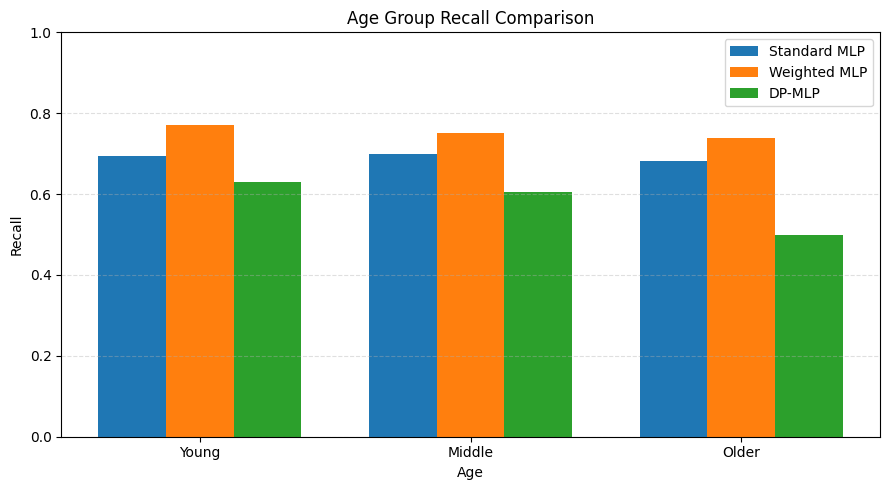

Saved: age_recall_comparison.png


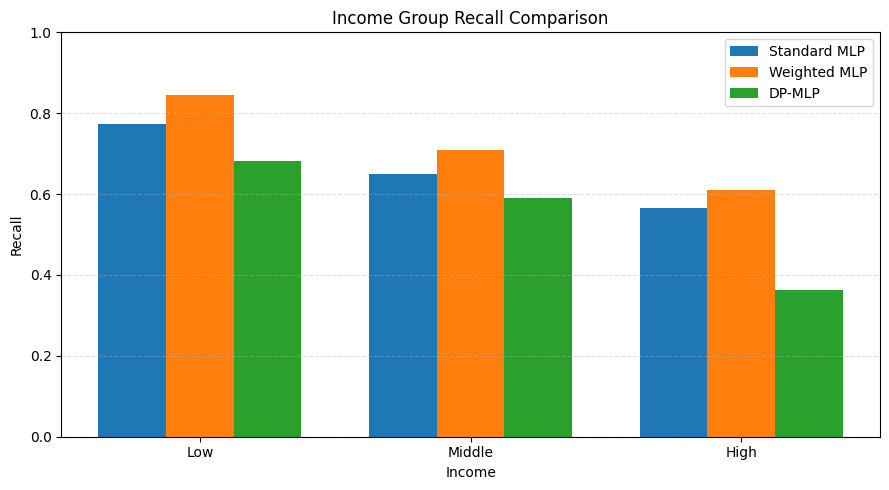

Saved: income_recall_comparison.png


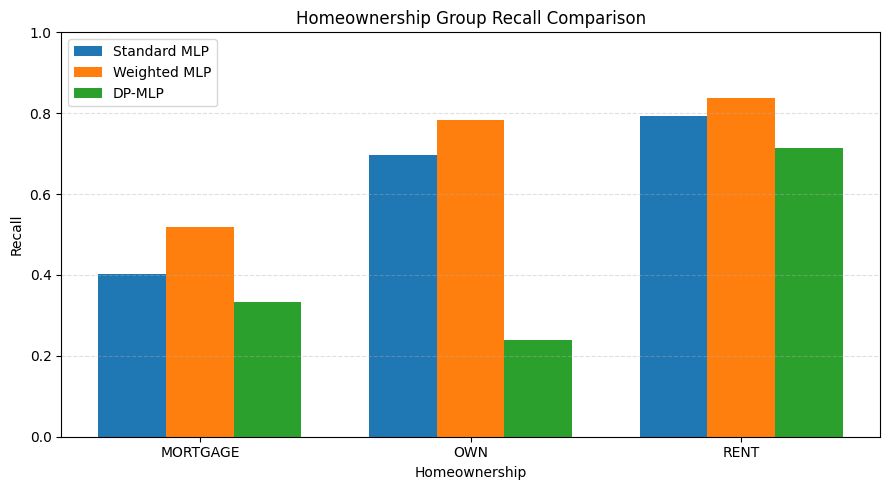

Saved: homeownership_recall_comparison.png

All recall comparison graphs generated successfully.


In [25]:
import os
import matplotlib.pyplot as plt
import numpy as np

# Create graphs directory
os.makedirs("../results/graphs", exist_ok=True)

# ============================================
# RECALL COMPARISON DATA
# ============================================

data = {
    "Age": {
        "groups": ["Young", "Middle", "Older"],
        "Standard MLP": [0.6954, 0.7003, 0.6812],
        "Weighted MLP": [0.7701, 0.7517, 0.7391],
        "DP-MLP": [0.62931, 0.60614, 0.50000]
    },

    "Income": {
        "groups": ["Low", "Middle", "High"],
        "Standard MLP": [0.7722, 0.6501, 0.5649],
        "Weighted MLP": [0.8440, 0.7095, 0.6104],
        "DP-MLP": [0.68147, 0.59069, 0.363636]
    },

    "Homeownership": {
        "groups": ["MORTGAGE", "OWN", "RENT"],
        "Standard MLP": [0.4035, 0.6957, 0.7930],
        "Weighted MLP": [0.5175, 0.7826, 0.8379],
        "DP-MLP": [0.333333, 0.239130, 0.714844]
    }
}

# ============================================
# GENERATE GRAPHS
# ============================================

models = ["Standard MLP", "Weighted MLP", "DP-MLP"]

for attribute, values in data.items():

    groups = values["groups"]
    x = np.arange(len(groups))
    width = 0.25

    fig, ax = plt.subplots(figsize=(9, 5))

    for i, model in enumerate(models):

        ax.bar(
            x + (i - 1) * width,
            values[model],
            width,
            label=model
        )

    ax.set_title(f"{attribute} Group Recall Comparison")
    ax.set_xlabel(attribute)
    ax.set_ylabel("Recall")
    ax.set_xticks(x)
    ax.set_xticklabels(groups)
    ax.set_ylim(0, 1)
    ax.legend()
    ax.grid(axis="y", linestyle="--", alpha=0.4)

    plt.tight_layout()

    filename = f"{attribute.lower()}_recall_comparison.png"

    plt.savefig(
        f"../results/graphs/{filename}",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print(f"Saved: {filename}")

print("\nAll recall comparison graphs generated successfully.")

In [26]:
import os

graph_dir = "../results/graphs"

expected_files = [
    "age_recall_comparison.png",
    "income_recall_comparison.png",
    "homeownership_recall_comparison.png"
]

print("===== GRAPH FILE VERIFICATION =====")

for filename in expected_files:
    path = os.path.join(graph_dir, filename)

    if os.path.exists(path):
        print(f"[OK] {filename}")
    else:
        print(f"[MISSING] {filename}")

===== GRAPH FILE VERIFICATION =====
[OK] age_recall_comparison.png
[OK] income_recall_comparison.png
[OK] homeownership_recall_comparison.png


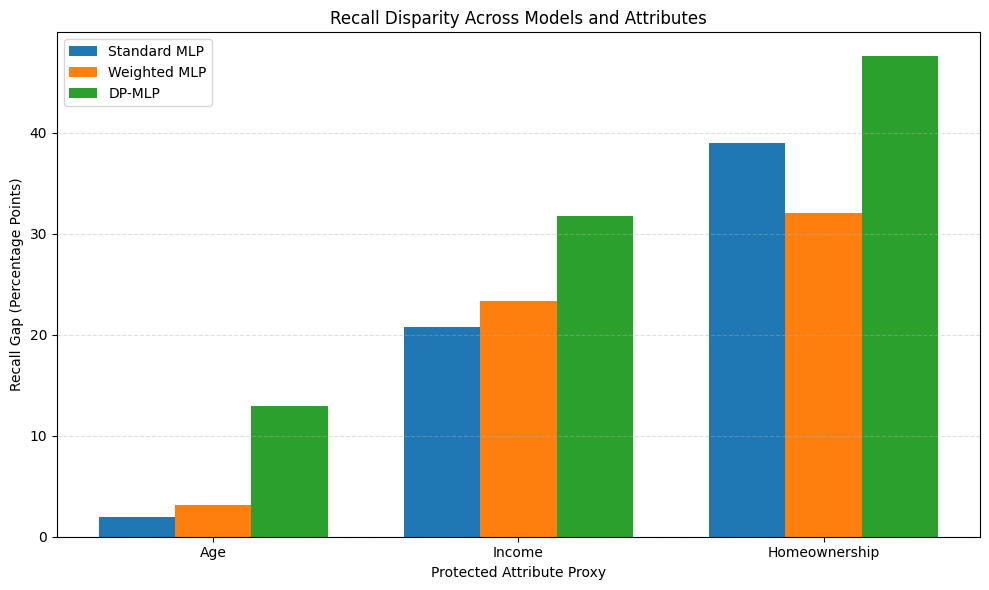

Recall disparity graph saved successfully.


In [27]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Create output directory
os.makedirs("../results/graphs", exist_ok=True)

# Verified disparity values (percentage points)
disparity_data = pd.DataFrame({
    "Attribute": ["Age", "Income", "Homeownership"],
    "Standard MLP": [1.91, 20.73, 38.95],
    "Weighted MLP": [3.10, 23.36, 32.04],
    "DP-MLP": [12.93, 31.78, 47.57]
})

# Plot
x = range(len(disparity_data))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 6))

models = ["Standard MLP", "Weighted MLP", "DP-MLP"]

for i, model in enumerate(models):
    ax.bar(
        [j + (i - 1) * width for j in x],
        disparity_data[model],
        width,
        label=model
    )

ax.set_title("Recall Disparity Across Models and Attributes")
ax.set_xlabel("Protected Attribute Proxy")
ax.set_ylabel("Recall Gap (Percentage Points)")
ax.set_xticks(list(x))
ax.set_xticklabels(disparity_data["Attribute"])
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig(
    "../results/graphs/recall_disparity_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Recall disparity graph saved successfully.")

In [28]:
import os
import pandas as pd

# ==========================================
# CONSOLIDATED MODEL RESULTS
# ==========================================

comparison_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Standard MLP",
        "Weighted MLP",
        "DP-MLP"
    ],

    "Accuracy": [
        0.8691,
        0.9212,
        0.8896,
        0.8837
    ],

    "Precision": [
        0.7728,
        0.9530,
        0.7417,
        0.8138
    ],

    "Recall": [
        0.5684,
        0.6728,
        0.7595,
        0.6072
    ],

    "F1": [
        0.6550,
        0.7888,
        0.7505,
        0.6955
    ],

    "ROC_AUC": [
        0.8680,
        0.9165,
        0.9180,
        0.8852
    ],

    "Epsilon": [
        None,
        None,
        None,
        1.3304
    ]
})

# ==========================================
# FAIRNESS DISPARITY RESULTS
# ==========================================

fairness_summary = pd.DataFrame({
    "Model": [
        "Standard MLP",
        "Weighted MLP",
        "DP-MLP"
    ],

    "Age_Recall_Gap_pp": [
        1.91,
        3.10,
        12.93
    ],

    "Income_Recall_Gap_pp": [
        20.73,
        23.36,
        31.78
    ],

    "Homeownership_Recall_Gap_pp": [
        38.95,
        32.04,
        47.57
    ]
})

# ==========================================
# DISPLAY
# ==========================================

print("===== MODEL UTILITY AND PRIVACY COMPARISON =====")
display(comparison_results.round(4))

print("\n===== MODEL FAIRNESS COMPARISON =====")
display(fairness_summary.round(2))

# ==========================================
# SAVE
# ==========================================

os.makedirs("../results", exist_ok=True)

comparison_results.to_csv(
    "../results/model_performance_comparison.csv",
    index=False
)

fairness_summary.to_csv(
    "../results/model_fairness_comparison.csv",
    index=False
)

print("\nComparison tables saved successfully.")

===== MODEL UTILITY AND PRIVACY COMPARISON =====


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Epsilon
0,Logistic Regression,0.8691,0.7728,0.5684,0.6550,0.8680,NaN
1,Standard MLP,0.9212,0.9530,0.6728,0.7888,0.9165,NaN
2,Weighted MLP,0.8896,0.7417,0.7595,0.7505,0.9180,NaN
3,DP-MLP,0.8837,0.8138,0.6072,0.6955,0.8852,1.3304



===== MODEL FAIRNESS COMPARISON =====


,Model,Age_Recall_Gap_pp,Income_Recall_Gap_pp,Homeownership_Recall_Gap_pp
0,Standard MLP,1.91,20.73,38.95
1,Weighted MLP,3.10,23.36,32.04
2,DP-MLP,12.93,31.78,47.57



Comparison tables saved successfully.


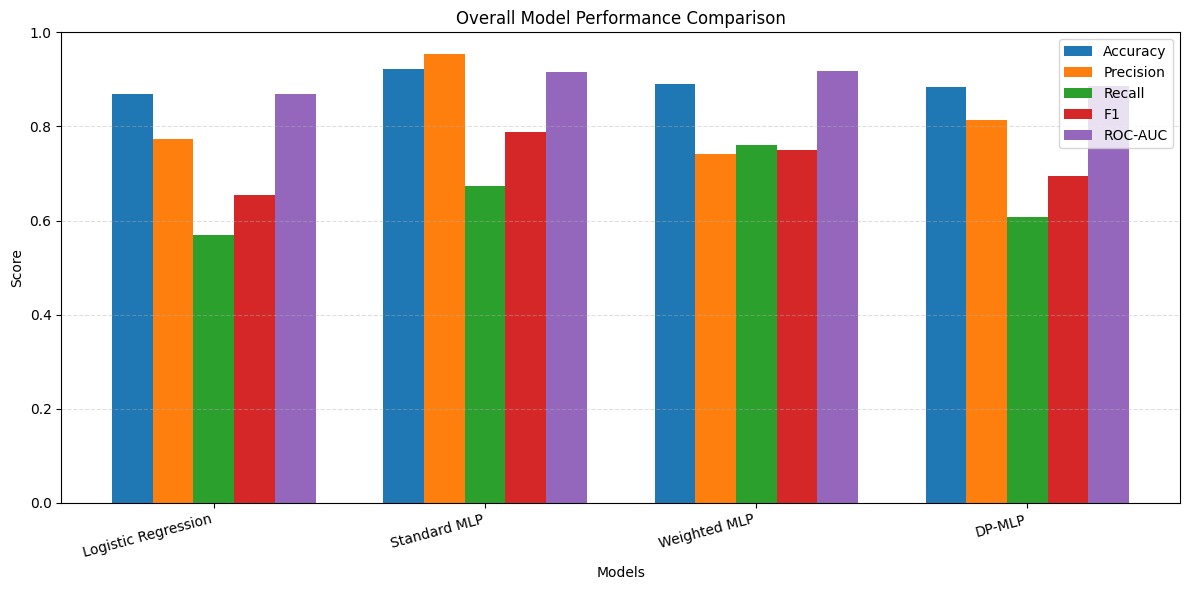

Model utility comparison graph saved successfully.


In [29]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Create graph directory
os.makedirs("../results/graphs", exist_ok=True)

# Verified model results
model_metrics = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Standard MLP",
        "Weighted MLP",
        "DP-MLP"
    ],
    "Accuracy": [0.8691, 0.9212, 0.8896, 0.8837],
    "Precision": [0.7728, 0.9530, 0.7417, 0.8138],
    "Recall": [0.5684, 0.6728, 0.7595, 0.6072],
    "F1": [0.6550, 0.7888, 0.7505, 0.6955],
    "ROC-AUC": [0.8680, 0.9165, 0.9180, 0.8852]
})

# Metrics to plot
metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]

# Plot
fig, ax = plt.subplots(figsize=(12, 6))

x = range(len(model_metrics))
width = 0.15

for i, metric in enumerate(metrics):
    ax.bar(
        [j + (i - 2) * width for j in x],
        model_metrics[metric],
        width,
        label=metric
    )

ax.set_title("Overall Model Performance Comparison")
ax.set_xlabel("Models")
ax.set_ylabel("Score")
ax.set_xticks(list(x))
ax.set_xticklabels(model_metrics["Model"], rotation=15, ha="right")
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

# Save graph
plt.savefig(
    "../results/graphs/model_utility_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Model utility comparison graph saved successfully.")

In [30]:
import pandas as pd
import os

# Verified results
standard = {
    "Accuracy": 0.9212,
    "Precision": 0.9530,
    "Recall": 0.6728,
    "F1": 0.7888,
    "ROC-AUC": 0.9165
}

dp = {
    "Accuracy": 0.8837,
    "Precision": 0.8138,
    "Recall": 0.6072,
    "F1": 0.6955,
    "ROC-AUC": 0.8852
}

# Calculate absolute change in percentage points
# and relative change in percentage
tradeoff_results = []

for metric in standard:

    absolute_change = (dp[metric] - standard[metric]) * 100

    relative_change = (
        (dp[metric] - standard[metric]) / standard[metric]
    ) * 100

    tradeoff_results.append({
        "Metric": metric,
        "Standard_MLP": standard[metric],
        "DP_MLP": dp[metric],
        "Change_pp": absolute_change,
        "Relative_Change_Percent": relative_change
    })

tradeoff_df = pd.DataFrame(tradeoff_results)

print("===== PRIVACY-UTILITY TRADE-OFF =====")
display(tradeoff_df.round(4))

# Save
os.makedirs("../results", exist_ok=True)

tradeoff_df.to_csv(
    "../results/privacy_utility_tradeoff.csv",
    index=False
)

print("\nPrivacy-utility analysis saved successfully.")
print("DP Privacy Budget (epsilon): 1.3304")
print("Delta: 1e-5")

===== PRIVACY-UTILITY TRADE-OFF =====


,Metric,Standard_MLP,DP_MLP,Change_pp,Relative_Change_Percent
0,Accuracy,0.9212,0.8837,-3.75,-4.0708
1,Precision,0.9530,0.8138,-13.92,-14.6065
2,Recall,0.6728,0.6072,-6.56,-9.7503
3,F1,0.7888,0.6955,-9.33,-11.8281
4,ROC-AUC,0.9165,0.8852,-3.13,-3.4152



Privacy-utility analysis saved successfully.
DP Privacy Budget (epsilon): 1.3304
Delta: 1e-5


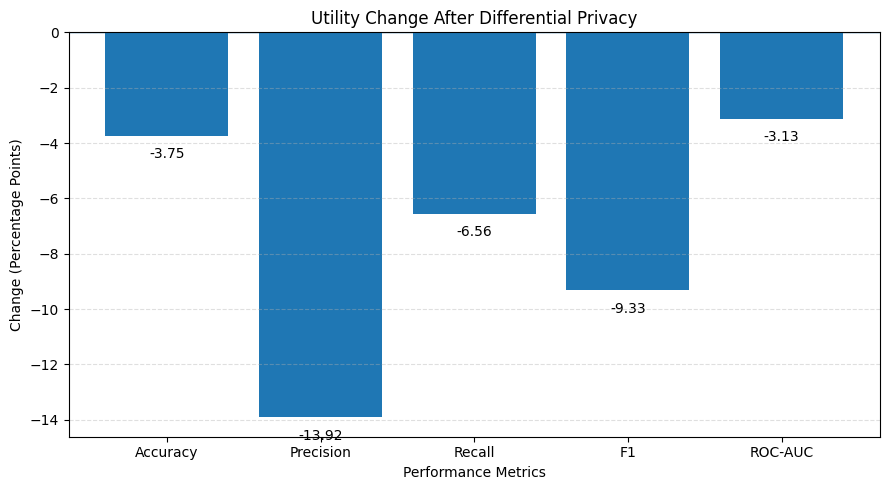

Privacy-utility loss graph saved successfully.


In [31]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Create directory
os.makedirs("../results/graphs", exist_ok=True)

# Verified privacy-utility changes (percentage points)
tradeoff = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"],
    "Change": [-3.75, -13.92, -6.56, -9.33, -3.13]
})

# Plot
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    tradeoff["Metric"],
    tradeoff["Change"]
)

ax.axhline(0, linewidth=1)
ax.set_title("Utility Change After Differential Privacy")
ax.set_xlabel("Performance Metrics")
ax.set_ylabel("Change (Percentage Points)")
ax.grid(axis="y", linestyle="--", alpha=0.4)

# Add labels
for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height - 0.4,
        f"{height:.2f}",
        ha="center",
        va="top"
    )

plt.tight_layout()

# Save graph
plt.savefig(
    "../results/graphs/privacy_utility_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Privacy-utility loss graph saved successfully.")

In [32]:
import os
import torch
import pandas as pd
import importlib

import src.dp_training as dp
importlib.reload(dp)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# ==========================================
# EXPERIMENT CONFIGURATION
# ==========================================

noise_multiplier = 1.5
epochs = 20
batch_size = 64
learning_rate = 0.001
max_grad_norm = 1.0
delta = 1e-5

print("===== DP EXPERIMENT: NOISE 1.5 =====")

# ==========================================
# TRAIN DP MODEL
# ==========================================

dp_model_15, epsilon_15 = dp.train_dp_mlp(
    X_train,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    learning_rate=learning_rate,
    noise_multiplier=noise_multiplier,
    max_grad_norm=max_grad_norm
)

# ==========================================
# EVALUATION
# ==========================================

dp_model_15.eval()

with torch.no_grad():
    outputs = dp_model_15(
        torch.tensor(X_test, dtype=torch.float32)
    )

    probabilities_15 = torch.sigmoid(outputs).numpy().flatten()
    predictions_15 = (probabilities_15 >= 0.5).astype(int)

metrics_15 = {
    "Accuracy": accuracy_score(y_test, predictions_15),
    "Precision": precision_score(y_test, predictions_15, zero_division=0),
    "Recall": recall_score(y_test, predictions_15, zero_division=0),
    "F1": f1_score(y_test, predictions_15, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, probabilities_15)
}

# ==========================================
# DISPLAY RESULTS
# ==========================================

print("\n===== DP MODEL PERFORMANCE =====")

for metric, value in metrics_15.items():
    print(f"{metric:10}: {value:.4f}")

print("\n===== PRIVACY ACCOUNTING =====")
print(f"Noise multiplier : {noise_multiplier}")
print(f"Max grad norm  : {max_grad_norm}")
print(f"Privacy epsilon : {epsilon_15:.4f}")
print(f"Delta          : {delta}")

# ==========================================
# SAVE MODEL AND METRICS
# ==========================================

os.makedirs("../models/dp", exist_ok=True)
os.makedirs("../results", exist_ok=True)

torch.save(
    dp_model_15.state_dict(),
    "../models/dp/dp_mlp_noise_1_5.pth"
)

results_15 = pd.DataFrame([{
    "Model": "DP-MLP",
    "Noise_Multiplier": noise_multiplier,
    "Epochs": epochs,
    "Batch_Size": batch_size,
    "Learning_Rate": learning_rate,
    "Max_Grad_Norm": max_grad_norm,
    "Epsilon": epsilon_15,
    "Delta": delta,
    **metrics_15
}])

results_15.to_csv(
    "../results/dp_noise_1_5_results.csv",
    index=False
)

print("\nModel and experiment results saved successfully.")

d:\Ethical_AI\FairDP_Research\.venv\lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
11/20/2026 16:05:42:WARNING:Ignoring drop_last as it is not compatible with DPDataLoader.


===== DP EXPERIMENT: NOISE 1.5 =====


d:\Ethical_AI\FairDP_Research\src\dp_training.py:82: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
  loss.backward()


Epoch [1/20] - DP Loss: 0.5472
Epoch [2/20] - DP Loss: 0.5180
Epoch [3/20] - DP Loss: 0.5005
Epoch [4/20] - DP Loss: 0.4879
Epoch [5/20] - DP Loss: 0.4665
Epoch [6/20] - DP Loss: 0.4704
Epoch [7/20] - DP Loss: 0.4487
Epoch [8/20] - DP Loss: 0.4721
Epoch [9/20] - DP Loss: 0.4715
Epoch [10/20] - DP Loss: 0.4590
Epoch [11/20] - DP Loss: 0.4555
Epoch [12/20] - DP Loss: 0.4698
Epoch [13/20] - DP Loss: 0.4563
Epoch [14/20] - DP Loss: 0.4537
Epoch [15/20] - DP Loss: 0.4501
Epoch [16/20] - DP Loss: 0.4484
Epoch [17/20] - DP Loss: 0.4506
Epoch [18/20] - DP Loss: 0.4343
Epoch [19/20] - DP Loss: 0.4433
Epoch [20/20] - DP Loss: 0.4555

===== PRIVACY ACCOUNTING =====
Noise multiplier : 1.5
Max grad norm  : 1.0
Privacy epsilon : 0.6640
Delta          : 1e-5

===== DP MODEL PERFORMANCE =====
Accuracy  : 0.8738
Precision : 0.7863
Recall    : 0.5811
F1        : 0.6683
ROC_AUC   : 0.8784

===== PRIVACY ACCOUNTING =====
Noise multiplier : 1.5
Max grad norm  : 1.0
Privacy epsilon : 0.6640
Delta          :

In [33]:
import torch
import os
import importlib
import src.fairness as fairness

importlib.reload(fairness)

# ==========================================
# GENERATE NOISE 1.5 PREDICTIONS
# ==========================================

dp_model_15.eval()

with torch.no_grad():
    outputs_15 = dp_model_15(
        torch.tensor(X_test, dtype=torch.float32)
    )

    probabilities_15 = torch.sigmoid(outputs_15).numpy().flatten()
    predictions_15 = (probabilities_15 >= 0.5).astype(int)

# ==========================================
# FAIRNESS EVALUATION
# ==========================================

age_fairness_15 = fairness.evaluate_group_metrics(
    y_test,
    predictions_15,
    X_test_raw["age_group"]
)

income_fairness_15 = fairness.evaluate_group_metrics(
    y_test,
    predictions_15,
    X_test_raw["income_group"]
)

home_fairness_15 = fairness.evaluate_group_metrics(
    y_test,
    predictions_15,
    X_test_raw["homeownership_group"]
)

# ==========================================
# DISPLAY
# ==========================================

print("===== DP NOISE 1.5 - AGE FAIRNESS =====")
display(age_fairness_15)

print("\n===== DP NOISE 1.5 - INCOME FAIRNESS =====")
display(income_fairness_15)

print("\n===== DP NOISE 1.5 - HOMEOWNERSHIP FAIRNESS =====")
display(home_fairness_15)

# ==========================================
# SAVE RESULTS
# ==========================================

os.makedirs("../results", exist_ok=True)

age_fairness_15.to_csv(
    "../results/age_fairness_dp_noise_1_5.csv",
    index=False
)

income_fairness_15.to_csv(
    "../results/income_fairness_dp_noise_1_5.csv",
    index=False
)

home_fairness_15.to_csv(
    "../results/homeownership_fairness_dp_noise_1_5.csv",
    index=False
)

print("\nNoise 1.5 fairness results saved successfully.")

===== DP NOISE 1.5 - AGE FAIRNESS =====


,Group,Samples,Accuracy,Precision,Recall,F1,Selection_Rate,FPR,FNR
0,Young,3013,0.874876,0.810916,0.597701,0.688172,0.170262,0.041864,0.402299
1,Middle,2744,0.873542,0.769932,0.578767,0.660802,0.159985,0.046759,0.421233
2,Older,727,0.870702,0.729167,0.507246,0.598291,0.132050,0.044143,0.492754



===== DP NOISE 1.5 - INCOME FAIRNESS =====


,Group,Samples,Accuracy,Precision,Recall,F1,Selection_Rate,FPR,FNR
0,Low,1577,0.819277,0.843629,0.681747,0.754098,0.328472,0.086538,0.318253
1,Middle,3189,0.878645,0.748945,0.569823,0.647220,0.148636,0.046376,0.430177
2,High,1718,0.915017,0.571429,0.207792,0.304762,0.032596,0.015345,0.792208



===== DP NOISE 1.5 - HOMEOWNERSHIP FAIRNESS =====


,Group,Samples,Accuracy,Precision,Recall,F1,Selection_Rate,FPR,FNR
0,MORTGAGE,2681,0.881761,0.580645,0.263158,0.362173,0.057814,0.027790,0.736842
1,OTHER,18,1.000000,1.000000,1.000000,1.000000,0.333333,0.000000,0.000000
2,OWN,521,0.892514,0.352941,0.260870,0.300000,0.065259,0.046316,0.739130
3,RENT,3264,0.863664,0.839390,0.699219,0.762920,0.261336,0.061161,0.300781



Noise 1.5 fairness results saved successfully.


In [34]:
import pandas as pd
import os

# ==========================================
# RECALL DATA: DP NOISE 1.0 vs 1.5
# ==========================================

dp_recall_comparison = {
    "Age": {
        "Groups": ["Young", "Middle", "Older"],
        "Noise_1_0": [0.62931, 0.60614, 0.50000],
        "Noise_1_5": [0.617947, 0.578767, 0.507246]
    },

    "Income": {
        "Groups": ["Low", "Middle", "High"],
        "Noise_1_0": [0.68147, 0.59069, 0.363636],
        "Noise_1_5": [0.681747, 0.569823, 0.27792]
    },

    "Homeownership": {
        "Groups": ["MORTGAGE", "OTHER", "OWN", "RENT"],
        "Noise_1_0": [0.333333, 0.666667, 0.239130, 0.714844],
        "Noise_1_5": [0.263158, 1.000000, 0.260870, 0.699219]
    }
}

# ==========================================
# CALCULATE RECALL GAPS
# ==========================================

gap_rows = []

for attribute, data in dp_recall_comparison.items():

    groups = data["Groups"]

    for noise_key in ["Noise_1_0", "Noise_1_5"]:

        recalls = data[noise_key]

        # All groups
        all_gap = (max(recalls) - min(recalls)) * 100

        # Exclude OTHER for homeownership
        if attribute == "Homeownership":
            main_recalls = [
                recall for group, recall in zip(groups, recalls)
                if group != "OTHER"
            ]
            main_gap = (max(main_recalls) - min(main_recalls)) * 100
        else:
            main_gap = all_gap

        gap_rows.append({
            "Attribute": attribute,
            "Noise": noise_key.replace("_", " "),
            "Recall_Gap_All_Groups_pp": all_gap,
            "Recall_Gap_Main_Groups_pp": main_gap
        })

dp_fairness_noise_comparison = pd.DataFrame(gap_rows)

print("===== DP FAIRNESS: NOISE 1.0 VS 1.5 =====")
display(dp_fairness_noise_comparison.round(2))

# ==========================================
# SAVE
# ==========================================

os.makedirs("../results", exist_ok=True)

dp_fairness_noise_comparison.to_csv(
    "../results/dp_fairness_noise_comparison.csv",
    index=False
)

print("\nDP fairness noise comparison saved successfully.")

===== DP FAIRNESS: NOISE 1.0 VS 1.5 =====


,Attribute,Noise,Recall_Gap_All_Groups_pp,Recall_Gap_Main_Groups_pp
0,Age,Noise 1 0,12.93,12.93
1,Age,Noise 1 5,11.07,11.07
2,Income,Noise 1 0,31.78,31.78
3,Income,Noise 1 5,40.38,40.38
4,Homeownership,Noise 1 0,47.57,47.57
5,Homeownership,Noise 1 5,73.91,43.83



DP fairness noise comparison saved successfully.


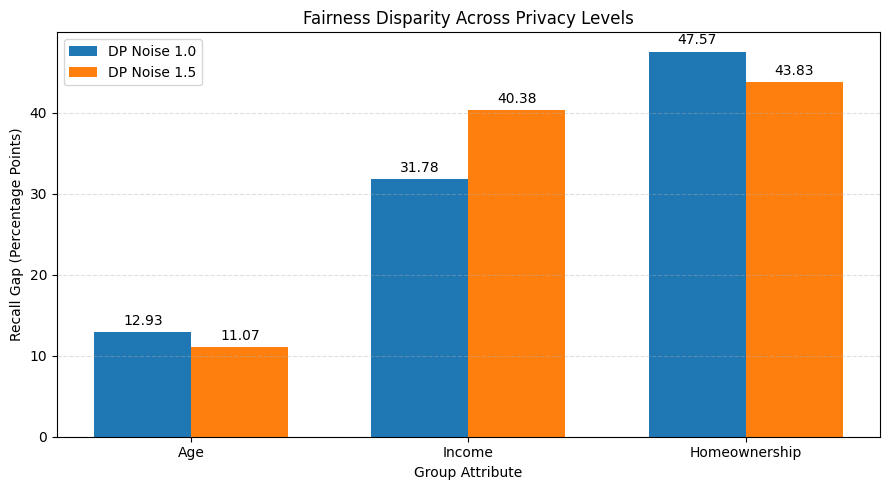

DP fairness privacy comparison graph saved successfully.


In [35]:
import os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs("../results/graphs", exist_ok=True)

# Verified recall disparity values (percentage points)
attributes = ["Age", "Income", "Homeownership"]

noise_1_0 = [12.93, 31.78, 47.57]
noise_1_5 = [11.07, 40.38, 43.83]

x = np.arange(len(attributes))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    x - width/2,
    noise_1_0,
    width,
    label="DP Noise 1.0"
)

ax.bar(
    x + width/2,
    noise_1_5,
    width,
    label="DP Noise 1.5"
)

ax.set_title("Fairness Disparity Across Privacy Levels")
ax.set_xlabel("Group Attribute")
ax.set_ylabel("Recall Gap (Percentage Points)")
ax.set_xticks(x)
ax.set_xticklabels(attributes)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

# Add value labels
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", padding=3)

plt.tight_layout()

plt.savefig(
    "../results/graphs/dp_fairness_privacy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("DP fairness privacy comparison graph saved successfully.")

===== DP PRIVACY LEVEL - UTILITY COMPARISON =====


,Metric,Noise_1_0,Noise_1_5,Change_pp
0,Accuracy,0.8837,0.8738,-0.99
1,Precision,0.8138,0.7863,-2.75
2,Recall,0.6072,0.5811,-2.61
3,F1,0.6955,0.6683,-2.72
4,ROC-AUC,0.8852,0.8784,-0.68


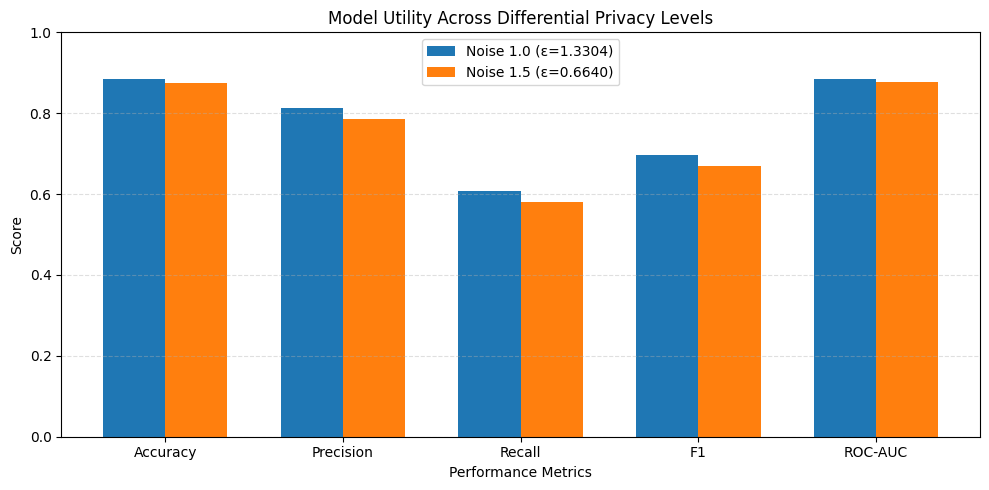

Privacy level utility comparison graph saved successfully.


In [36]:
import pandas as pd
import os
import matplotlib.pyplot as plt

# ==========================================
# VERIFIED DP MODEL RESULTS
# ==========================================

dp_comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"],
    "Noise_1_0": [0.8837, 0.8138, 0.6072, 0.6955, 0.8852],
    "Noise_1_5": [0.8738, 0.7863, 0.5811, 0.6683, 0.8784]
})

# ==========================================
# CALCULATE CHANGE
# ==========================================

dp_comparison["Change_pp"] = (
    dp_comparison["Noise_1_5"] -
    dp_comparison["Noise_1_0"]
) * 100

print("===== DP PRIVACY LEVEL - UTILITY COMPARISON =====")
display(dp_comparison.round(4))

# ==========================================
# SAVE TABLE
# ==========================================

os.makedirs("../results/graphs", exist_ok=True)

dp_comparison.to_csv(
    "../results/dp_privacy_level_utility_comparison.csv",
    index=False
)

# ==========================================
# VISUALIZATION
# ==========================================

fig, ax = plt.subplots(figsize=(10, 5))

x = range(len(dp_comparison))
width = 0.35

ax.bar(
    [i - width/2 for i in x],
    dp_comparison["Noise_1_0"],
    width,
    label="Noise 1.0 (ε=1.3304)"
)

ax.bar(
    [i + width/2 for i in x],
    dp_comparison["Noise_1_5"],
    width,
    label="Noise 1.5 (ε=0.6640)"
)

ax.set_title("Model Utility Across Differential Privacy Levels")
ax.set_xlabel("Performance Metrics")
ax.set_ylabel("Score")
ax.set_xticks(list(x))
ax.set_xticklabels(dp_comparison["Metric"])
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig(
    "../results/graphs/dp_privacy_level_utility_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Privacy level utility comparison graph saved successfully.")

In [37]:
import os
import torch
import importlib
import src.dp_training as dp

importlib.reload(dp)

# ==========================================
# EXPERIMENT CONFIGURATION
# ==========================================

noise_multiplier = 2.0
epochs = 20
batch_size = 64
learning_rate = 0.001
max_grad_norm = 1.0
delta = 1e-5

# ==========================================
# TRAIN MODEL
# ==========================================

print("===== DP EXPERIMENT: NOISE 2.0 =====")

dp_model_20, epsilon_20 = dp.train_dp_mlp(
    X_train,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    learning_rate=learning_rate,
    noise_multiplier=noise_multiplier,
    max_grad_norm=max_grad_norm
)

# ==========================================
# SAVE MODEL
# ==========================================

os.makedirs("../models/dp", exist_ok=True)

torch.save(
    dp_model_20.state_dict(),
    "../models/dp/dp_mlp_noise_2_0.pth"
)

print("\n===== PRIVACY ACCOUNTING =====")
print(f"Noise multiplier : {noise_multiplier}")
print(f"Max grad norm  : {max_grad_norm}")
print(f"Privacy epsilon : {epsilon_20:.4f}")
print(f"Delta          : {delta}")

print("\nDP Noise 2.0 model saved successfully.")

d:\Ethical_AI\FairDP_Research\.venv\lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
11/20/2026 16:29:28:WARNING:Ignoring drop_last as it is not compatible with DPDataLoader.


===== DP EXPERIMENT: NOISE 2.0 =====


d:\Ethical_AI\FairDP_Research\src\dp_training.py:82: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
  loss.backward()


Epoch [1/20] - DP Loss: 0.5316
Epoch [2/20] - DP Loss: 0.5089
Epoch [3/20] - DP Loss: 0.4950
Epoch [4/20] - DP Loss: 0.4707
Epoch [5/20] - DP Loss: 0.4716
Epoch [6/20] - DP Loss: 0.4655
Epoch [7/20] - DP Loss: 0.4526
Epoch [8/20] - DP Loss: 0.4604
Epoch [9/20] - DP Loss: 0.4641
Epoch [10/20] - DP Loss: 0.4415
Epoch [11/20] - DP Loss: 0.4366
Epoch [12/20] - DP Loss: 0.4607
Epoch [13/20] - DP Loss: 0.4494
Epoch [14/20] - DP Loss: 0.4539
Epoch [15/20] - DP Loss: 0.4438
Epoch [16/20] - DP Loss: 0.4463
Epoch [17/20] - DP Loss: 0.4539
Epoch [18/20] - DP Loss: 0.4318
Epoch [19/20] - DP Loss: 0.4444
Epoch [20/20] - DP Loss: 0.4510

===== PRIVACY ACCOUNTING =====
Noise multiplier : 2.0
Max grad norm  : 1.0
Privacy epsilon : 0.4567
Delta          : 1e-5

===== PRIVACY ACCOUNTING =====
Noise multiplier : 2.0
Max grad norm  : 1.0
Privacy epsilon : 0.4567
Delta          : 1e-05

DP Noise 2.0 model saved successfully.


In [38]:
import torch
import pandas as pd
import os

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# ==========================================
# DP NOISE 2.0 - MODEL EVALUATION
# ==========================================

dp_model_20.eval()

with torch.no_grad():
    outputs_20 = dp_model_20(
        torch.tensor(X_test, dtype=torch.float32)
    )

    probabilities_20 = torch.sigmoid(outputs_20).numpy().flatten()
    predictions_20 = (probabilities_20 >= 0.5).astype(int)

# ==========================================
# CALCULATE METRICS
# ==========================================

metrics_20 = {
    "Accuracy": accuracy_score(y_test, predictions_20),
    "Precision": precision_score(y_test, predictions_20, zero_division=0),
    "Recall": recall_score(y_test, predictions_20, zero_division=0),
    "F1": f1_score(y_test, predictions_20, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, probabilities_20)
}

# ==========================================
# DISPLAY
# ==========================================

print("===== DP MLP PERFORMANCE (NOISE 2.0) =====")

for metric, value in metrics_20.items():
    print(f"{metric:10}: {value:.4f}")

print("\n===== PRIVACY ACCOUNTING =====")
print(f"Noise multiplier : 2.0")
print(f"Privacy epsilon  : {epsilon_20:.4f}")
print(f"Delta           : 1e-5")

# ==========================================
# SAVE RESULTS
# ==========================================

os.makedirs("../results", exist_ok=True)

results_20 = pd.DataFrame([{
    "Model": "DP-MLP",
    "Noise_Multiplier": 2.0,
    "Epsilon": epsilon_20,
    "Delta": 1e-5,
    **metrics_20
}])

results_20.to_csv(
    "../results/dp_noise_2_0_results.csv",
    index=False
)

print("\nNoise 2.0 evaluation results saved successfully.")

===== DP MLP PERFORMANCE (NOISE 2.0) =====
Accuracy  : 0.8760
Precision : 0.8252
Recall    : 0.5494
F1        : 0.6596
ROC_AUC   : 0.8767

===== PRIVACY ACCOUNTING =====
Noise multiplier : 2.0
Privacy epsilon  : 0.4567
Delta           : 1e-5

Noise 2.0 evaluation results saved successfully.


In [39]:
import torch
import os
import importlib
import src.fairness as fairness

importlib.reload(fairness)

# ==========================================
# DP NOISE 2.0 PREDICTIONS
# ==========================================

dp_model_20.eval()

with torch.no_grad():
    outputs_20 = dp_model_20(
        torch.tensor(X_test, dtype=torch.float32)
    )

    probabilities_20 = torch.sigmoid(outputs_20).numpy().flatten()
    predictions_20 = (probabilities_20 >= 0.5).astype(int)

# ==========================================
# FAIRNESS EVALUATION
# ==========================================

age_fairness_20 = fairness.evaluate_group_metrics(
    y_test,
    predictions_20,
    X_test_raw["age_group"]
)

income_fairness_20 = fairness.evaluate_group_metrics(
    y_test,
    predictions_20,
    X_test_raw["income_group"]
)

home_fairness_20 = fairness.evaluate_group_metrics(
    y_test,
    predictions_20,
    X_test_raw["homeownership_group"]
)

# ==========================================
# DISPLAY RESULTS
# ==========================================

print("===== DP NOISE 2.0 - AGE FAIRNESS =====")
display(age_fairness_20)

print("\n===== DP NOISE 2.0 - INCOME FAIRNESS =====")
display(income_fairness_20)

print("\n===== DP NOISE 2.0 - HOMEOWNERSHIP FAIRNESS =====")
display(home_fairness_20)

# ==========================================
# SAVE RESULTS
# ==========================================

os.makedirs("../results", exist_ok=True)

age_fairness_20.to_csv(
    "../results/age_fairness_dp_noise_2_0.csv",
    index=False
)

income_fairness_20.to_csv(
    "../results/income_fairness_dp_noise_2_0.csv",
    index=False
)

home_fairness_20.to_csv(
    "../results/homeownership_fairness_dp_noise_2_0.csv",
    index=False
)

print("\nDP Noise 2.0 fairness results saved successfully.")

===== DP NOISE 2.0 - AGE FAIRNESS =====


,Group,Samples,Accuracy,Precision,Recall,F1,Selection_Rate,FPR,FNR
0,Young,3013,0.879522,0.849057,0.581897,0.690537,0.158314,0.031075,0.418103
1,Middle,2744,0.874271,0.813648,0.530822,0.642487,0.138848,0.032870,0.469178
2,Older,727,0.867950,0.744186,0.463768,0.571429,0.118294,0.037351,0.536232



===== DP NOISE 2.0 - INCOME FAIRNESS =====


,Group,Samples,Accuracy,Precision,Recall,F1,Selection_Rate,FPR,FNR
0,Low,1577,0.816107,0.855984,0.658346,0.744268,0.312619,0.075855,0.341654
1,Middle,3189,0.881468,0.802469,0.521669,0.632296,0.126999,0.031177,0.478331
2,High,1718,0.920838,0.695652,0.207792,0.320000,0.026775,0.008951,0.792208



===== DP NOISE 2.0 - HOMEOWNERSHIP FAIRNESS =====


,Group,Samples,Accuracy,Precision,Recall,F1,Selection_Rate,FPR,FNR
0,MORTGAGE,2681,0.887355,0.672414,0.228070,0.340611,0.043267,0.016246,0.771930
1,OTHER,18,0.944444,1.000000,0.833333,0.909091,0.277778,0.000000,0.166667
2,OWN,521,0.892514,0.352941,0.260870,0.300000,0.065259,0.046316,0.739130
3,RENT,3264,0.863664,0.866920,0.667969,0.754550,0.241728,0.046875,0.332031



DP Noise 2.0 fairness results saved successfully.


In [40]:
import pandas as pd
import os

# ==========================================
# RECORDED RECALL VALUES FOR ALL DP MODELS
# ==========================================

recall_data = {
    "Age": {
        "groups": ["Young", "Middle", "Older"],
        "Noise_1_0": [0.62931, 0.60614, 0.50000],
        "Noise_1_5": [0.617947, 0.578767, 0.507246],
        "Noise_2_0": [0.581897, 0.530822, 0.463768]
    },

    "Income": {
        "groups": ["Low", "Middle", "High"],
        "Noise_1_0": [0.68147, 0.59069, 0.363636],
        "Noise_1_5": [0.681747, 0.569823, 0.27792],
        "Noise_2_0": [0.658346, 0.521669, 0.27792]
    },

    "Homeownership": {
        "groups": ["MORTGAGE", "OTHER", "OWN", "RENT"],
        "Noise_1_0": [0.333333, 0.666667, 0.239130, 0.714844],
        "Noise_1_5": [0.263158, 1.000000, 0.260870, 0.699219],
        "Noise_2_0": [0.228070, 0.833333, 0.260870, 0.669796]
    }
}

# ==========================================
# CALCULATE RECALL DISPARITIES
# ==========================================

rows = []

for attribute, data in recall_data.items():

    groups = data["groups"]

    for noise in ["Noise_1_0", "Noise_1_5", "Noise_2_0"]:

        recalls = data[noise]

        # Disparity across all groups
        gap_all = (max(recalls) - min(recalls)) * 100

        # Exclude OTHER for homeownership
        if attribute == "Homeownership":

            main_recalls = [
                recall
                for group, recall in zip(groups, recalls)
                if group != "OTHER"
            ]

            gap_main = (
                max(main_recalls) - min(main_recalls)
            ) * 100

        else:
            gap_main = gap_all

        rows.append({
            "Attribute": attribute,
            "Privacy_Level": noise.replace("_", " "),
            "Recall_Gap_All_Groups_pp": gap_all,
            "Recall_Gap_Main_Groups_pp": gap_main
        })

# Create table
dp_fairness_all_levels = pd.DataFrame(rows)

print("===== FAIRNESS COMPARISON: ALL DP PRIVACY LEVELS =====")
display(dp_fairness_all_levels.round(2))

# ==========================================
# SAVE RESULTS
# ==========================================

os.makedirs("../results", exist_ok=True)

dp_fairness_all_levels.to_csv(
    "../results/dp_fairness_all_privacy_levels.csv",
    index=False
)

print("\nAll DP fairness comparison results saved successfully.")

===== FAIRNESS COMPARISON: ALL DP PRIVACY LEVELS =====


,Attribute,Privacy_Level,Recall_Gap_All_Groups_pp,Recall_Gap_Main_Groups_pp
0,Age,Noise 1 0,12.93,12.93
1,Age,Noise 1 5,11.07,11.07
2,Age,Noise 2 0,11.81,11.81
3,Income,Noise 1 0,31.78,31.78
4,Income,Noise 1 5,40.38,40.38
5,Income,Noise 2 0,38.04,38.04
6,Homeownership,Noise 1 0,47.57,47.57
7,Homeownership,Noise 1 5,73.91,43.83
8,Homeownership,Noise 2 0,60.53,44.17



All DP fairness comparison results saved successfully.


In [ ]:
import matplotlib.pyplot as plt
import os
import numpy as np

os.makedirs("../results/graphs", exist_ok=True)

privacy_levels = ["Noise 1.0", "Noise 1.5", "Noise 2.0"]

fairness_gaps = {
    "Age": [12.93, 11.07, 11.81],
    "Income": [31.78, 40.38, 38.04],
    "Homeownership (excluding OTHER)": [47.57, 43.83, 44.17]
}

# ============================================
# GENERATE INDIVIDUAL FAIRNESS GRAPHS
# ============================================

for attribute, values in fairness_gaps.items():

    plt.figure(figsize=(8, 5))

    bars = plt.bar(privacy_levels, values)

    plt.title(f"DP Fairness Comparison - {attribute}")
    plt.xlabel("Privacy Noise Level")
    plt.ylabel("Recall Disparity (Percentage Points)")
    plt.grid(axis="y", linestyle="--", alpha=0.4)

    # Value labels
    for bar, value in zip(bars, values):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.5,
            f"{value:.2f}",
            ha="center"
        )

    plt.tight_layout()

    filename = attribute.lower().replace(" ", "_").replace("(", "").replace(")", "")

    plt.savefig(
        f"../results/graphs/dp_fairness_{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("All three DP fairness comparison graphs saved successfully.")

SyntaxError: '(' was never closed (3165958935.py, line 41)